Generate reproducible nonlinear data between 0 and 20, with 80 data points. Generate random noise and add realistic variation to the output data. Use pipeline model to calculate the training and testing MSE for degrees 1, 2, and 10. Analyse the bias and variance trade-offs. Plot the fitted models. 


Polynomial Degree: 1
Training MSE: 475.1008120955662
Testing MSE: 573.1482167931515

Polynomial Degree: 2
Training MSE: 209.46096096950973
Testing MSE: 166.79889934038562

Polynomial Degree: 10
Training MSE: 167.77233817230277
Testing MSE: 279.4053083358045


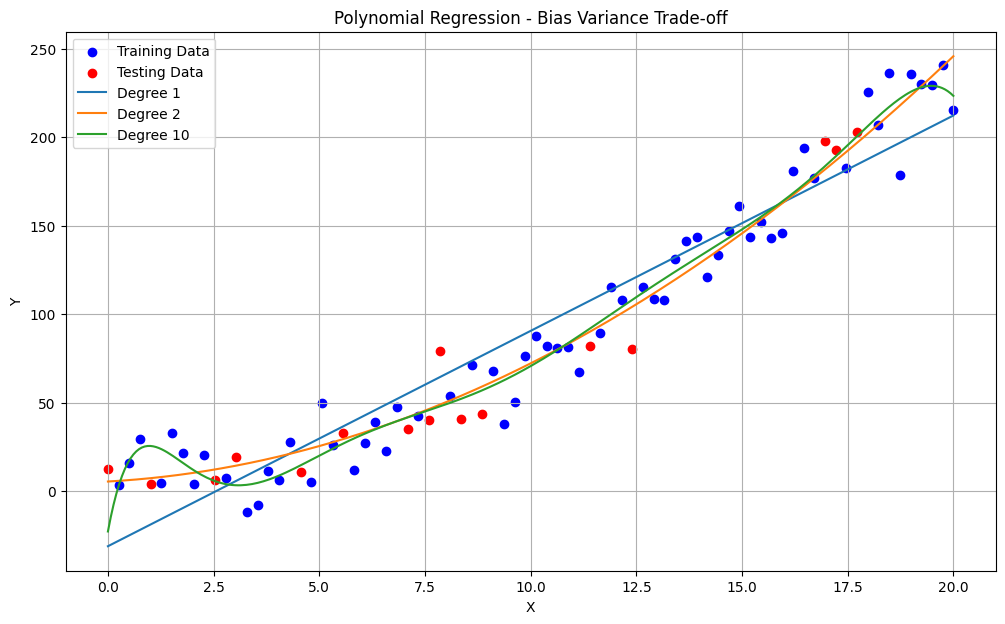

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# Generate reproducible nonlinear data
np.random.seed(42)

X = np.linspace(0, 20, 80).reshape(-1, 1)

# Generate nonlinear output with random noise
y = 5 + 2 * X.ravel() + 0.5 * X.ravel()**2 + np.random.normal(0, 15, 80)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Polynomial degrees
degrees = [1, 2, 10]

# Plot original data
plt.figure(figsize=(12, 7))
plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.scatter(X_test, y_test, color='red', label='Testing Data')

# Train and evaluate models
for degree in degrees:

    # Create pipeline
    model = make_pipeline(
        PolynomialFeatures(degree=degree),
        StandardScaler(),
        LinearRegression()
    )

    # Train model
    model.fit(X_train, y_train)

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    # Calculate MSE
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)

    print("\nPolynomial Degree:", degree)
    print("Training MSE:", train_mse)
    print("Testing MSE:", test_mse)

    # Generate predictions for plotting
    X_plot = np.linspace(0, 20, 300).reshape(-1, 1)
    y_plot = model.predict(X_plot)

    plt.plot(X_plot, y_plot, label=f'Degree {degree}')

# Plot formatting
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Polynomial Regression - Bias Variance Trade-off")
plt.legend()
plt.grid()
plt.show()